# 💜 Dating Recommendations – Matching System

**Project type:** Recommender Systems · Content-Based Recommendation · Python

In this project, we explore a small dating-app dataset and build a simple **profile recommendation system** using shared interests, relationship goals, and age similarity.

We will:
- Inspect the dataset and check data quality.
- Explore ages, relationship goals, and interests with visualizations.
- Discover common interest combinations.
- Build an easy-to-understand matching score and explain the recommendations.

**Important:** The score is a hand-designed similarity measure, **not** a trained machine learning model or a prediction of real relationship success.

## 1. Dataset and libraries

The dataset contains **500 profiles** with 11 original columns. The most useful fields for this project are `Age`, `Interests`, and `Looking For`.

The original data dictionary describes `Height` as centimeters, but the numerical values (about 4.8–6.1) do not support that unit. We do not use height in matching. The meaning of `Children` and `Swiping History` is also not sufficiently precise to use them as matching preferences.

In [1]:
import ast
import pandas as pd
import matplotlib.pyplot as plt

,User ID,Age,Gender,Height,Interests,Looking For,Children,Education Level,Occupation,Swiping History,Frequency of Usage
0,1,30,Male,5.240385,"['Sports', 'Cooking', 'Hiking', 'Music', 'Movi...",Casual Dating,No,High School,Student,96,Weekly
1,2,27,Female,4.937625,"['Sports', 'Reading']",Friendship,Yes,Master's Degree,Artist,96,Monthly
2,3,29,Female,5.806296,['Sports'],Casual Dating,No,Bachelor's Degree,Social Media Influencer,64,Daily
3,4,29,Female,5.101402,['Reading'],Marriage,No,Ph.D.,Doctor,67,Daily
4,5,32,Male,5.986670,"['Sports', 'Hiking', 'Music', 'Movies', 'Readi...",Long-term Relationship,Yes,Ph.D.,Engineer,93,Monthly


In [ ]:
df = pd.read_csv("dating_app_dataset.csv")
df.head()

## 2. Data quality checks

We check dataset size, missing values, duplicate users, and age range. The `Interests` column contains text representations of Python lists, so we convert it using `ast.literal_eval` (instead of unsafe `eval`).

In [2]:
print("Rows and columns:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate User IDs:", df["User ID"].duplicated().sum())
print("Age range:", df["Age"].min(), "to", df["Age"].max())

df["Interests_list"] = df["Interests"].apply(ast.literal_eval)
print("All interests parsed as lists:", df["Interests_list"].apply(lambda x: isinstance(x, list)).all())

Rows and columns: (500, 11)
Missing values: 0
Duplicate User IDs: 0
Age range: 18 to 35
All interests parsed as lists: True


## 3. Exploratory Data Analysis (EDA)

### 3.1 Age distribution

Are most users around the same age, or are they spread across the sample?

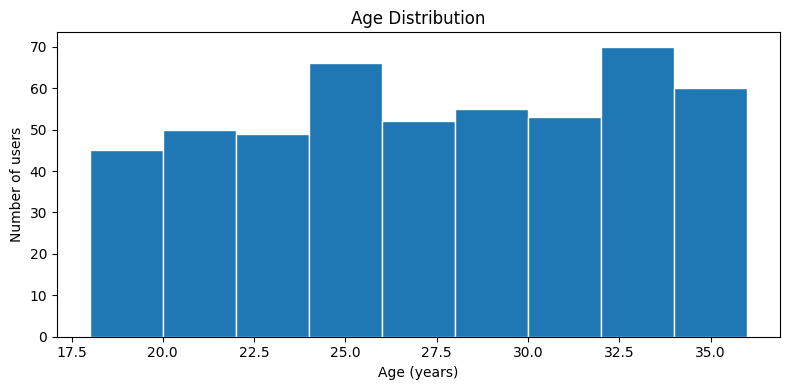

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(df["Age"], bins=range(18, 38, 2), edgecolor="white")
plt.title("Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Number of users")
plt.tight_layout()
plt.show()

### 3.2 What are users looking for?

Relationship goals matter in a recommendation system because two users with different goals may not be seeking the same kind of connection.

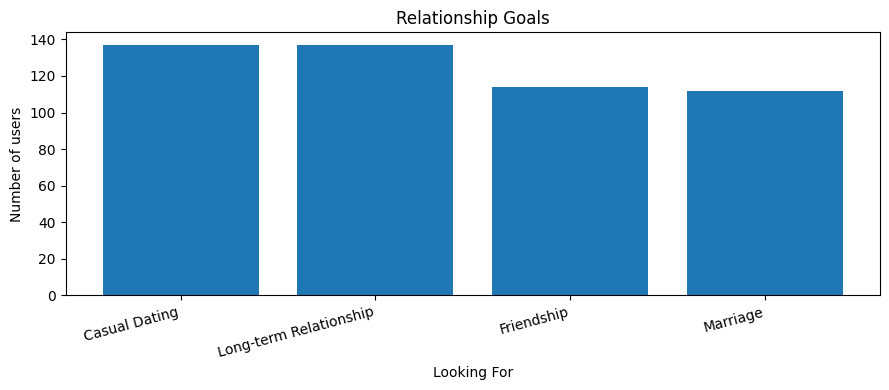

In [4]:
goal_counts = df["Looking For"].value_counts()

plt.figure(figsize=(9, 4))
plt.bar(goal_counts.index, goal_counts.values)
plt.title("Relationship Goals")
plt.xlabel("Looking For")
plt.ylabel("Number of users")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### 3.3 Most popular interests

We count interests across all profiles. A user can choose several interests, so the total exceeds the number of profiles.

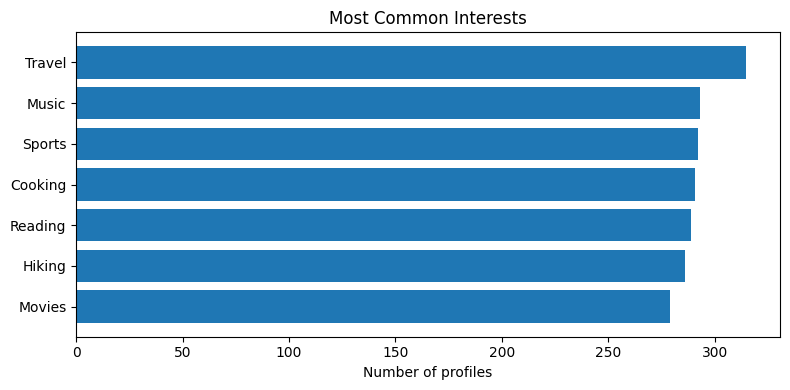

Most common interest: Travel (315 of 500 profiles)


In [5]:
interest_counts = pd.Series([
    interest
    for interests in df["Interests_list"]
    for interest in interests
]).value_counts()

plt.figure(figsize=(8, 4))
plt.barh(interest_counts.index[::-1], interest_counts.values[::-1])
plt.title("Most Common Interests")
plt.xlabel("Number of profiles")
plt.tight_layout()
plt.show()

print("Most common interest:", interest_counts.index[0],
      f"({interest_counts.iloc[0]} of {len(df)} profiles)")

### 3.4 An extra insight: Which interests appear together?

Most analyses stop after counting individual interests. Here we also count how often **two interests appear in the same profile**.

**Interpretation note:** Popular interests naturally create larger co-occurrence counts. This chart does not prove that the interests are statistically related.

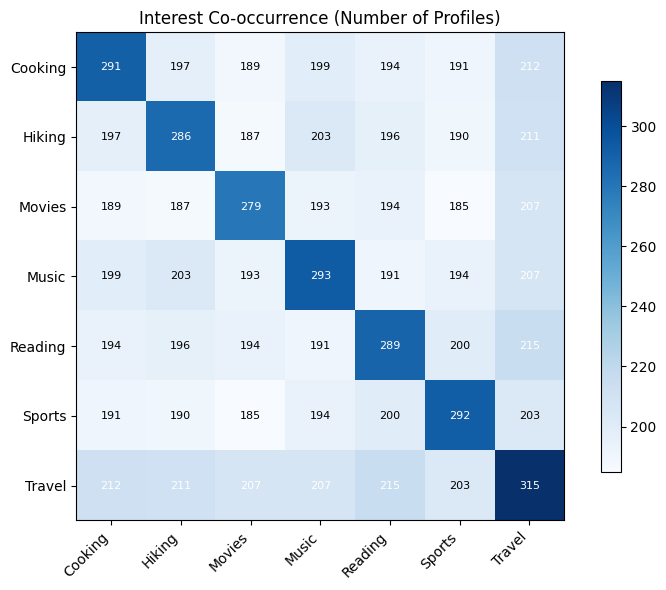

In [6]:
interests = sorted(interest_counts.index)
interest_matrix = pd.DataFrame({
    item: df["Interests_list"].apply(lambda values: item in values).astype(int)
    for item in interests
})
co_occurrence = interest_matrix.T.dot(interest_matrix)

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(co_occurrence, cmap="Blues")
ax.set_xticks(range(len(interests)), interests, rotation=45, ha="right")
ax.set_yticks(range(len(interests)), interests)
ax.set_title("Interest Co-occurrence (Number of Profiles)")
for i in range(len(interests)):
    for j in range(len(interests)):
        ax.text(j, i, int(co_occurrence.iloc[i, j]),
                ha="center", va="center", fontsize=8,
                color="white" if co_occurrence.iloc[i,j] > co_occurrence.values.max()*0.65 else "black")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

### 3.5 How many interests does each user list?

If many profiles list nearly every available hobby, shared interests alone may not distinguish candidates very well.

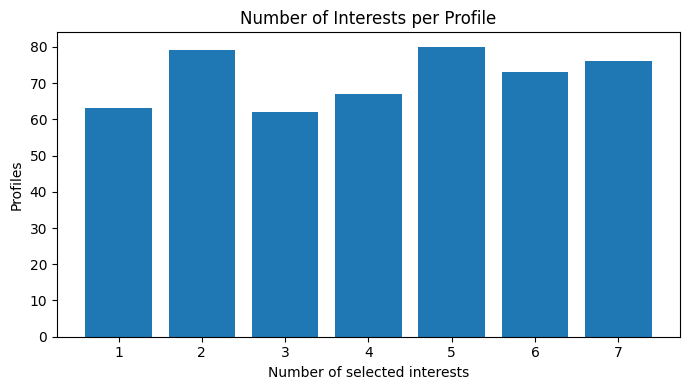

Profiles listing all 7 interests: 76


In [7]:
df["Interest Count"] = df["Interests_list"].apply(len)
count_dist = df["Interest Count"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(count_dist.index, count_dist.values)
plt.title("Number of Interests per Profile")
plt.xlabel("Number of selected interests")
plt.ylabel("Profiles")
plt.xticks(count_dist.index)
plt.tight_layout()
plt.show()

print(f"Profiles listing all {len(interests)} interests:",
      (df["Interest Count"] == len(interests)).sum())

## 4. Build a simple matching system

We calculate a transparent **similarity score (0–100)** based on:

| Feature | Weight | How it works |
|---|---:|---|
| Shared interests | 50% | Jaccard similarity: shared interests divided by all unique interests |
| Same relationship goal | 30% | 1 if goals match, otherwise 0 |
| Age similarity | 20% | Higher for closer ages; reaches 0 when the age gap is 15+ years |

These weights are **illustrative choices**, not values validated by real user feedback. We do **not** infer gender preferences or filter profiles by gender, because the dataset does not contain that preference.

In [8]:
def match_score(user, candidate):
    a = set(user["Interests_list"])
    b = set(candidate["Interests_list"])

    common_interests = len(a & b) / len(a | b) if a | b else 0
    same_goal = int(user["Looking For"] == candidate["Looking For"])
    age_similarity = max(0, 1 - abs(user["Age"] - candidate["Age"]) / 15)

    return round(100 * (0.5 * common_interests +
                        0.3 * same_goal +
                        0.2 * age_similarity), 1)

print("Example similarity score:", match_score(df.iloc[0], df.iloc[1]))

Example similarity score: 30.3


## 5. Recommend the top 5 profiles

Select a `User ID` and calculate the best matches across all other profiles. The output explains each recommendation through common interests and shared goals.

In [9]:
def recommend_profiles(user_id, top_n=5):
    user = df.loc[df["User ID"] == user_id]
    if user.empty:
        raise ValueError("User ID not found")
    user = user.iloc[0]

    candidates = df.loc[df["User ID"] != user_id].copy()
    candidates["Score"] = candidates.apply(lambda row: match_score(user, row), axis=1)
    candidates["Shared Interests"] = candidates["Interests_list"].apply(
        lambda values: ", ".join(sorted(set(user["Interests_list"]) & set(values))) or "None"
    )
    candidates["Same Goal"] = candidates["Looking For"].eq(user["Looking For"])

    return candidates.sort_values(["Score", "User ID"], ascending=[False, True])[
        ["User ID", "Age", "Looking For", "Shared Interests", "Same Goal", "Score"]
    ].head(top_n)

user_id = 1  # Change this number to try another profile
recommendations = recommend_profiles(user_id)
recommendations

,User ID,Age,Looking For,Shared Interests,Same Goal,Score
103,104,31,Casual Dating,"Cooking, Hiking, Movies, Music, Reading, Sport...",True,98.7
225,226,31,Casual Dating,"Cooking, Hiking, Movies, Music, Reading, Sport...",True,98.7
177,178,28,Casual Dating,"Cooking, Hiking, Movies, Music, Reading, Sport...",True,97.3
490,491,32,Casual Dating,"Cooking, Hiking, Movies, Music, Reading, Sport...",True,97.3
98,99,33,Casual Dating,"Cooking, Hiking, Movies, Music, Reading, Sport...",True,96.0


### 5.1 Visualize recommendation scores

A score is easier to interpret when we compare the recommended candidates side by side.

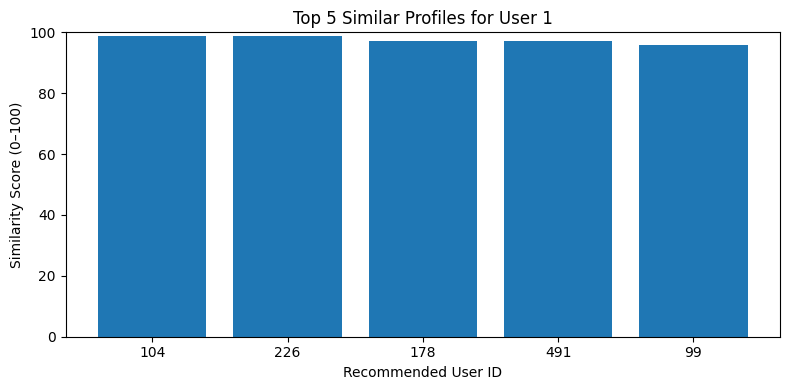

In [10]:
plt.figure(figsize=(8, 4))
plt.bar(recommendations["User ID"].astype(str), recommendations["Score"])
plt.title(f"Top 5 Similar Profiles for User {user_id}")
plt.xlabel("Recommended User ID")
plt.ylabel("Similarity Score (0–100)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 6. Findings and limitations

**Data observations**
- The dataset has **500 profiles** and **11 original columns**, with no missing values or duplicate User IDs.
- Users are **18–35 years old**, so this sample cannot describe every age group.
- **Travel** is the most frequent interest (315 profiles). **76 profiles list all seven available interests**. This means shared interests may not differentiate some profiles well.
- The dataset contains relationship goals, but not the preferences each user has for a potential partner.

**Model limitations**
- This is a **rule-based, content-based recommender**, not a trained model.
- A high similarity score is **not** a probability of success, attraction, or mutual interest.
- We cannot measure true recommendation accuracy without feedback such as mutual likes, conversations, or successful matches.
- The `Height` units and the interpretation of `Children` and `Swiping History` are unclear; these fields are excluded from scoring.
- Real dating systems would need consent, user-set preferences, privacy safeguards, and fairness evaluation.

## 7. Conclusion

This project demonstrates how to turn simple profile data into a transparent recommendation system. Exploratory analysis reveals useful patterns, while the scoring function shows **why** profiles are suggested. The most important lesson is to distinguish **similarity** from **real compatibility** and clearly communicate data limitations.